# 110장 · 성능·호출 비용 · 방향과 예시

사용자가 답을 기다린 시간을 줄이고 싶습니다. 이때 로컬 함수의 처리 시간과 화면이 뜰 때까지의 시간을 섞어 재면 바꿀 곳을 잘못 고를 수 있습니다. 한 요청의 시작과 끝부터 표시해 봅니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.

## 시간의 시작점과 끝점 정하기

측정 카드 예시　Q01 / rules-v1 / 공개 그룹 / 시작은 서비스 처리 직전 / 종료는 결과 검증과 JSON 저장이 끝난 시점 / 업무 결과 answered / 근거 RULE-A. 실제 사용자 대기는 브라우저 전송과 표시 시간까지 더 관찰해야 합니다. 아래 숫자는 단위를 연습하기 위해 만든 합성 시각입니다.

<!-- motion:stopwatch-span -->
**12와 15.5라는 눈금 사이에서 잰 값은 무엇일까요?**

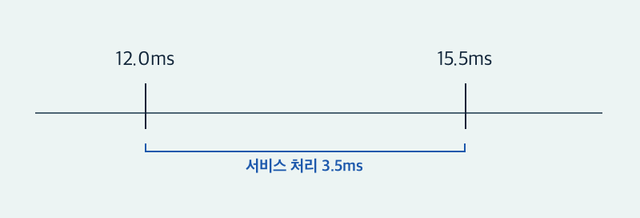

서비스 시작과 종료에 찍은 합성 시각의 차이는 3.5ms입니다. 브라우저에서 요청을 보내고 답을 그리는 시간은 이 두 눈금 밖에 있습니다.
<!-- /motion -->


### 셀 01 · 합성 시각을 밀리초로 바꾸기

두 값은 같은 시계의 나노초 눈금입니다. 날짜처럼 해석하지 말고 차이를 구해 보세요.

실패 시도의 기록 예는 ‘종료 사건 timeout / 성공 여부 False / 브라우저 대기 시간 미측정’입니다. Q01의 정상 완료 기록과 구분하세요. 관찰하지 못한 시간 칸에 0을 적으면 즉시 끝났다는 뜻으로 읽힙니다.

In [1]:
started_ns = 12_000_000
finished_ns = 15_500_000
elapsed_ms = (finished_ns - started_ns) / 1_000_000
print(elapsed_ms, "ms (합성 시각)")

3.5 ms (합성 시각)


3.5ms는 이 두 고정 숫자의 차이입니다. 팀이 실제 시간을 잴 때는 같은 장비와 자료, 같은 시작·종료 위치에서 여러 번 관찰하고 실패한 시도도 남깁니다.

## 빠른 답이 같은 답인지 살피기

비교표 한 행의 예시　대상 Q01 / 가설 “같은 공개 문서의 읽기 준비를 줄일 수 있다” / 고정 기준 본문 전원 표시등, RULE-A·2.1절·판본·허용 범위 / 바꾸려는 부분 문서 준비 횟수 / 결정 실측 전 보류. 현재 예제는 외부 모델 호출 0회입니다. 측정하지 않은 운영비와 청구 토큰을 비용 0원으로 적을 근거는 없습니다.


### 과제 02 · 선택 연습 · 비용 칸을 채울 수 있는지 보기

모델 호출은 없었지만 서비스의 청구 자료는 아직 받지 못했습니다. 현재 측정 범위를 한 줄로 정리하세요.

In [2]:
# 호출 수와 실제 운영 비용의 미확인 상태를 한 기록에 남기세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>record = {&quot;model_calls&quot;: 0, &quot;actual_operating_cost&quot;: None, &quot;source&quot;: &quot;로컬 규칙 실행&quot;}
print(record[&quot;source&quot;], record[&quot;model_calls&quot;], record[&quot;actual_operating_cost&quot;])</code></pre>
<p>실행 결과</p><pre><code>로컬 규칙 실행 0 None</code></pre>
<p>0은 관찰한 모델 호출 수입니다. None은 운영비를 측정하지 않았다는 뜻입니다. 팀에 청구서가 생기면 기간·통화·포함 항목부터 확인하세요.</p>
</details>

## 돌아보기

111장에는 측정 구간, 자료·질문 버전, 같은 결과를 보장하는 기준을 함께 넘기세요. 실제 HTTP 지연이나 청구서를 확보하기 전에는 운영 시간과 비용을 빈칸으로 둡니다.